# Where Should the Next High-End Eco-Coffee Shop Go?

## NYC Community District Opportunity Analysis

**Capstone deliverable:** a reproducible location-screening notebook for a high-end, eco-friendly coffee chain considering its next New York City store.

**Decision supported:** rank all 55 Community District reporting groups in the 2020 NYC Neighborhood Financial Health (NFH) release and recommend five priority districts for real-estate review.

**Core caveat:** this is a relative screening model. It uses public demographic and park-access data, not rent, foot traffic, competitor density, or store-level sales. The output is a shortlist for due diligence, not a final lease decision.


## 1. Business question and scope

A high-end coffee chain wants a district where affluent households can support premium pricing, where foot traffic is likely to be strong, and where green-space access supports an eco-friendly brand promise. The analysis therefore combines:

- **Demand:** median household income and poverty rate.
- **Eco-amenity:** number of park properties and waterfront park share.
- **Comparability:** all 55 NFH Community District reporting groups, not a hand-picked Manhattan subset.

The score is intentionally interpretable. It is a weighted percentile index, so each input is placed on the same 0-100 scale before weighting. Raw park acreage is reported but is **not** used in the score because a few very large parks would dominate the ranking and would not represent everyday café foot traffic.


## 2. Data sources

Both datasets are official NYC Open Data (Socrata) releases. Data were downloaded and cached on **2026-11-27**.

| Role | Dataset | Why it is used | Source |
|---|---|---|---|
| Primary | NYC Neighborhood Financial Health, 2020 | One comparable row per Community District reporting group; income and poverty | `https://data.cityofnewyork.us/resource/r3dx-pew9.json` |
| Secondary | NYC Parks Properties | Park count, acreage, waterfront status; different domain and different publisher workflow | `https://data.cityofnewyork.us/resource/enfh-gkve.json` |

No Kaggle data are used. The two files are joined on NYC Community District codes.

**Primary dataset caveat:** four NFH records cover two Community Districts each: `MN 1&2`, `MN 4&5`, `BX 1&2`, and `BX 3&6`. The analysis preserves those reporting groups rather than inventing separate income values that do not exist in the source.


In [1]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid", context="notebook")

def find_module_root(start):
    start = Path(start).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "data" / "raw" / "capstone").is_dir():
            return candidate
    return start

BASE_DIR = find_module_root(Path.cwd())
RAW_DIR = BASE_DIR / "data" / "raw" / "capstone"
PROCESSED_DIR = BASE_DIR / "data" / "processed"
RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

NFH_PATH = RAW_DIR / "nyc_neighborhood_financial_health_2020.csv"
PARKS_PATH = RAW_DIR / "nyc_parks_properties.csv"

SOCRATA_BASE = "https://data.cityofnewyork.us/resource/"
DATASETS = {
    "nfh": ("r3dx-pew9", NFH_PATH),
    "parks": ("enfh-gkve", PARKS_PATH),
}

def load_socrata(dataset_id, local_path):
    if local_path.exists():
        return pd.read_csv(local_path, dtype=str)
    response = requests.get(
        SOCRATA_BASE + dataset_id + ".json",
        params={"$limit": 50000},
        timeout=120,
    )
    response.raise_for_status()
    frame = pd.DataFrame(response.json())
    frame.to_csv(local_path, index=False)
    return frame

nfh_raw = load_socrata(*DATASETS["nfh"])
parks_raw = load_socrata(*DATASETS["parks"])

print(f"NFH raw shape: {nfh_raw.shape}")
print(f"Parks raw shape: {parks_raw.shape}")
print(f"NFH unique goals: {nfh_raw['goal'].nunique()}")
print(f"NFH unique CD labels: {nfh_raw['cd'].nunique()}")
print(f"Parks classes: {parks_raw['class'].value_counts().to_dict()}")
print(f"Parks retired values: {parks_raw['retired'].value_counts(dropna=False).to_dict()}")


NFH raw shape: (385, 52)
Parks raw shape: (2061, 33)
NFH unique goals: 7
NFH unique CD labels: 55
Parks classes: {'PARK': 2061}
Parks retired values: {'False': 2061}


## 3. Data Cleaning Log

Each major decision is recorded with the business reason for it. Counts in the log are checked by the next code cell.

1. **Kept only `goal == "Overall Index"` from the 2020 NFH release.** The raw file stacks seven goal families; using only the overall row creates one comparable observation per district. This leaves 55 reporting groups covering 59 Community Districts because four pairs are combined in the source.

2. **Parsed the four combined labels into their component district codes while keeping the combined reporting row.** For example, `MN Community Districts 1 & 2` becomes codes `101` and `102`, but income and poverty remain the published combined values. This lets parks attach to both halves without fabricating separate income estimates.

3. **Kept parks with `class == "PARK"`, `retired == False`, and `acres > 0`.** Closed, retired, and non-park properties would overstate usable green space. After filtering, 2,061 active park properties remain.

4. **Split multi-district `communityboard` strings and allocated each property's acreage equally across its listed districts.** A park listed as `108111` is split 50/50 between districts 108 and 111. Equal allocation is transparent and avoids double-counting the whole property twice; it is an approximation because exact park boundaries are not used.

5. **Converted numeric strings to numbers and reviewed missing values before scoring.** Income, poverty, acres, park count, and waterfront share are complete after aggregation. One original park record has a missing waterfront flag; it is treated as not waterfront, which is conservative for the eco-amenity score.

6. **Did not use raw park acreage in the score.** A few very large parks would dominate the ranking and would not represent daily café foot traffic; park count and waterfront share are better proxies for accessible amenity. Raw acreage is retained in the audit table for transparency.

7. **Used percentile ranks, then min-max scaled the weighted index to 0-100.** Ranks reduce the influence of extreme income values and put dollars, percentages, and counts on a common scale. Poverty enters the score with a negative sign because higher poverty weakens premium demand.

8. **Aggregated to exactly one row per NFH reporting group and checked uniqueness.** The merged table has 55 rows, no duplicate district labels, and no missing values in the four score inputs. Where a district has no matched park, park metrics are set to zero rather than dropped so the district remains in the comparison.


In [2]:
overall = nfh_raw.loc[nfh_raw["goal"].eq("Overall Index")].copy()

BOROUGH_PREFIX = {"MN": 1, "BX": 2, "BK": 3, "QN": 4, "SI": 5}

def parse_nfh_codes(label):
    match = re.match(r"(MN|BX|BK|QN|SI) Community Districts? (.+)", str(label).strip())
    if not match:
        return []
    prefix = BOROUGH_PREFIX[match.group(1)]
    numbers = re.findall(r"\d+", match.group(2))
    return [prefix * 100 + int(number) for number in numbers]

overall["cd_codes"] = overall["cd"].apply(parse_nfh_codes)
overall["n_codes"] = overall["cd_codes"].str.len()

for column in ["median_income", "nyc_poverty_rate"]:
    overall[column] = pd.to_numeric(overall[column], errors="coerce")

overall["district_short"] = (
    overall["neighborhoods"].str.split(",").str[0].str.strip()
    + " ("
    + overall["borough"].str.strip()
    + ")"
)

print(f"Overall Index rows: {len(overall)}")
print(f"Rows with no parsed CD: {int(overall['n_codes'].eq(0).sum())}")
print(f"Combined reporting groups: {int(overall['n_codes'].gt(1).sum())}")
print(f"Missing income: {int(overall['median_income'].isna().sum())}")
print(f"Missing poverty: {int(overall['nyc_poverty_rate'].isna().sum())}")
display(overall[["cd", "borough", "neighborhoods", "median_income", "nyc_poverty_rate", "cd_codes"]].head(8))


Overall Index rows: 55
Rows with no parsed CD: 0
Combined reporting groups: 4
Missing income: 0
Missing poverty: 0


,cd,borough,neighborhoods,median_income,nyc_poverty_rate,cd_codes
5,BX Community District 8,Bronx,"Riverdale, Fieldston & Kingsbridge",30437,0.152,[208]
8,BX Community District 7,Bronx,"Bedford Park, Fordham North & Norwood",18674,0.264,[207]
13,BX Community District 12,Bronx,"Wakefield, Williamsbridge & Woodlawn",26136,0.232,[212]
21,BX Community District 10,Bronx,"Coop City, Pelham Bay & Schuylerville",31573,0.140,[210]
26,MN Community District 9,Manhattan,"Hamilton Heights, Manhattanville & West Harlem",24561,0.235,[109]
29,BX Community District 11,Bronx,"Pelham Parkway, Morris Park & Laconia",25358,0.205,[211]
37,BX Community Districts 3 & 6,Bronx,"Belmont, Crotona Park East & East Tremont",14213,0.308,"[203, 206]"
49,BX Community District 5,Bronx,"Morris Heights, Fordham South & Mount Hope",15628,0.344,[205]


In [3]:
parks = parks_raw.copy()
parks["acres_numeric"] = pd.to_numeric(parks["acres"], errors="coerce")
parks["retired_flag"] = parks["retired"].astype(str).str.lower().eq("true")
parks["waterfront_flag"] = parks["waterfront"].astype(str).str.lower().eq("true")

parks_clean = parks.loc[
    parks["class"].eq("PARK")
    & ~parks["retired_flag"]
    & parks["acres_numeric"].gt(0)
].copy()

def parse_community_board(value):
    codes = [int(code) for code in re.findall(r"\d{3}", str(value))]
    valid = sorted({code for code in codes if 101 <= code <= 512})
    return valid

parks_clean["cd_codes"] = parks_clean["communityboard"].apply(parse_community_board)
parks_clean["n_codes"] = parks_clean["cd_codes"].str.len()
parks_clean = parks_clean.loc[parks_clean["n_codes"].gt(0)].copy()
parks_clean["allocated_acres"] = parks_clean["acres_numeric"] / parks_clean["n_codes"]
parks_clean["allocated_waterfront_acres"] = np.where(
    parks_clean["waterfront_flag"], parks_clean["allocated_acres"], 0.0
)

parks_long = parks_clean.explode("cd_codes").copy()
parks_long["cd_code"] = parks_long["cd_codes"].astype(int)

park_agg = (
    parks_long.groupby("cd_code", as_index=False)
    .agg(
        park_count=("globalid", "nunique"),
        park_acres=("allocated_acres", "sum"),
        waterfront_acres=("allocated_waterfront_acres", "sum"),
    )
)

print(f"Active park properties used: {len(parks_clean)}")
print(f"Park properties with multi-district board codes: {int(parks_clean['n_codes'].gt(1).sum())}")
print(f"Distinct park properties: {parks_clean['globalid'].nunique()}")
print(f"Aggregated CD codes: {len(park_agg)}")
display(park_agg.head())


Active park properties used: 2061
Park properties with multi-district board codes: 59
Distinct park properties: 2061
Aggregated CD codes: 60


,cd_code,park_count,park_acres,waterfront_acres
0,101,20,67.925000,49.478
1,102,37,24.833000,0.000
2,103,83,117.421000,53.389
3,104,18,24.099000,0.000
4,105,10,163.902667,0.000


In [4]:
park_lookup = park_agg.set_index("cd_code")

for column in ["park_count", "park_acres", "waterfront_acres"]:
    overall[column] = overall["cd_codes"].apply(
        lambda codes: float(park_lookup.loc[codes, column].sum()) if codes else 0.0
    )

overall["park_count"] = overall["park_count"].fillna(0).astype(int)
overall["park_acres"] = overall["park_acres"].fillna(0.0)
overall["waterfront_acres"] = overall["waterfront_acres"].fillna(0.0)
overall["waterfront_share"] = np.where(
    overall["park_acres"].gt(0),
    overall["waterfront_acres"] / overall["park_acres"],
    0.0,
)

merged = overall.copy()
merged["park_count"] = merged["park_count"].fillna(0).astype(int)

core_columns = ["median_income", "nyc_poverty_rate", "park_count", "waterfront_share"]
assert len(merged) == 55
assert merged["cd"].is_unique
assert merged[core_columns].isna().sum().sum() == 0
assert merged["waterfront_share"].between(0, 1).all()

print(f"Analysis rows: {len(merged)}")
print(f"Duplicate CD labels: {int(merged['cd'].duplicated().sum())}")
print(f"Missing score inputs: {int(merged[core_columns].isna().sum().sum())}")
print(f"Park acre range: {merged['park_acres'].min():.2f} to {merged['park_acres'].max():.2f}")
display(
    merged[
        ["cd", "borough", "neighborhoods", "median_income", "nyc_poverty_rate", "park_count", "waterfront_share"]
    ].head(10)
)


Analysis rows: 55


Duplicate CD labels: 0
Missing score inputs: 0
Park acre range: 14.99 to 3474.21


,cd,borough,neighborhoods,median_income,nyc_poverty_rate,park_count,waterfront_share
5,BX Community District 8,Bronx,"Riverdale, Fieldston & Kingsbridge",30437,0.152,33,0.200980
8,BX Community District 7,Bronx,"Bedford Park, Fordham North & Norwood",18674,0.264,25,0.266379
13,BX Community District 12,Bronx,"Wakefield, Williamsbridge & Woodlawn",26136,0.232,17,0.787616
21,BX Community District 10,Bronx,"Coop City, Pelham Bay & Schuylerville",31573,0.140,25,0.933696
26,MN Community District 9,Manhattan,"Hamilton Heights, Manhattanville & West Harlem",24561,0.235,28,0.618584
29,BX Community District 11,Bronx,"Pelham Parkway, Morris Park & Laconia",25358,0.205,17,0.429423
37,BX Community Districts 3 & 6,Bronx,"Belmont, Crotona Park East & East Tremont",14213,0.308,94,0.559006
49,BX Community District 5,Bronx,"Morris Heights, Fordham South & Mount Hope",15628,0.344,40,0.127834
52,MN Community District 6,Manhattan,"Murray Hill, Gramercy & Stuyvesant Town",73067,0.100,23,0.019510
57,BX Community District 4,Bronx,"Concourse, Highbridge & Mount Eden",16710,0.323,47,0.087809


## 4. Coffee Viability Score

The score is a weighted percentile index. Each input is converted to a percentile rank across the 55 reporting groups, then combined:

```text
raw_score =
    0.65 x income_percentile
  - 0.20 x poverty_percentile
  + 0.10 x park_count_percentile
  + 0.05 x waterfront_share_percentile

Coffee_Viability_Score = 100 x (raw_score - min(raw_score)) / (max(raw_score) - min(raw_score))
```

**Interpretation of weights:** income receives the largest weight because premium coffee depends on discretionary spending. Poverty is a negative demand signal. Park count and waterfront share contribute 15% combined as an eco-amenity tie-breaker. The weights sum to 1.00 before the negative sign is applied to poverty.

This is a judgement-based index, not a causal model. It is designed to make the trade-offs explicit and easy to challenge.


In [5]:
score_inputs = {
    "median_income": ("Income percentile", 0.65, 1),
    "nyc_poverty_rate": ("Poverty percentile", 0.20, -1),
    "park_count": ("Park-count percentile", 0.10, 1),
    "waterfront_share": ("Waterfront-share percentile", 0.05, 1),
}

raw_score = pd.Series(0.0, index=merged.index)

for column, (label, weight, direction) in score_inputs.items():
    percentile_column = column + "_pct"
    merged[percentile_column] = merged[column].rank(pct=True)
    raw_score = raw_score + (weight * direction * merged[percentile_column])

merged["raw_score"] = raw_score
merged["Coffee_Viability_Score"] = (
    (merged["raw_score"] - merged["raw_score"].min())
    / (merged["raw_score"].max() - merged["raw_score"].min())
    * 100
).round(1)

merged = merged.sort_values("Coffee_Viability_Score", ascending=False).reset_index(drop=True)
merged["rank"] = np.arange(1, len(merged) + 1)

assert merged["Coffee_Viability_Score"].between(0, 100).all()
assert merged["Coffee_Viability_Score"].is_monotonic_decreasing

top5 = merged.head(5).copy()
display(
    top5[
        [
            "rank",
            "district_short",
            "borough",
            "median_income",
            "nyc_poverty_rate",
            "park_count",
            "waterfront_share",
            "Coffee_Viability_Score",
        ]
    ].rename(
        columns={
            "district_short": "district",
            "median_income": "median_income_usd",
            "nyc_poverty_rate": "poverty_rate",
            "Coffee_Viability_Score": "score",
        }
    )
)


,rank,district,borough,median_income_usd,poverty_rate,park_count,waterfront_share,score
0,1,Battery Park City (Manhattan),Manhattan,79181,0.088,57,0.533410,100.0
1,2,Upper West Side & West Side (Manhattan),Manhattan,65844,0.090,30,0.524160,89.0
2,3,Park Slope (Brooklyn),Brooklyn,57393,0.095,36,0.336450,88.2
3,4,Upper East Side (Manhattan),Manhattan,71933,0.073,18,0.180658,88.1
4,5,Murray Hill (Manhattan),Manhattan,73067,0.100,23,0.019510,88.0


## 5. Dashboard

The three panels answer three different stakeholder questions:

1. **Where is the opportunity?** Score distribution by borough, so a reader can see whether the shortlist is concentrated or broad.
2. **What is driving the score?** Income versus viability, with park count as bubble size and waterfront share as colour. This shows the positive income relationship and the eco-amenity overlay.
3. **What should we act on?** The top five districts, with scores and borough colours for a direct shortlist.

The figure is saved as `data/processed/capstone_dashboard.png` and displayed inline.


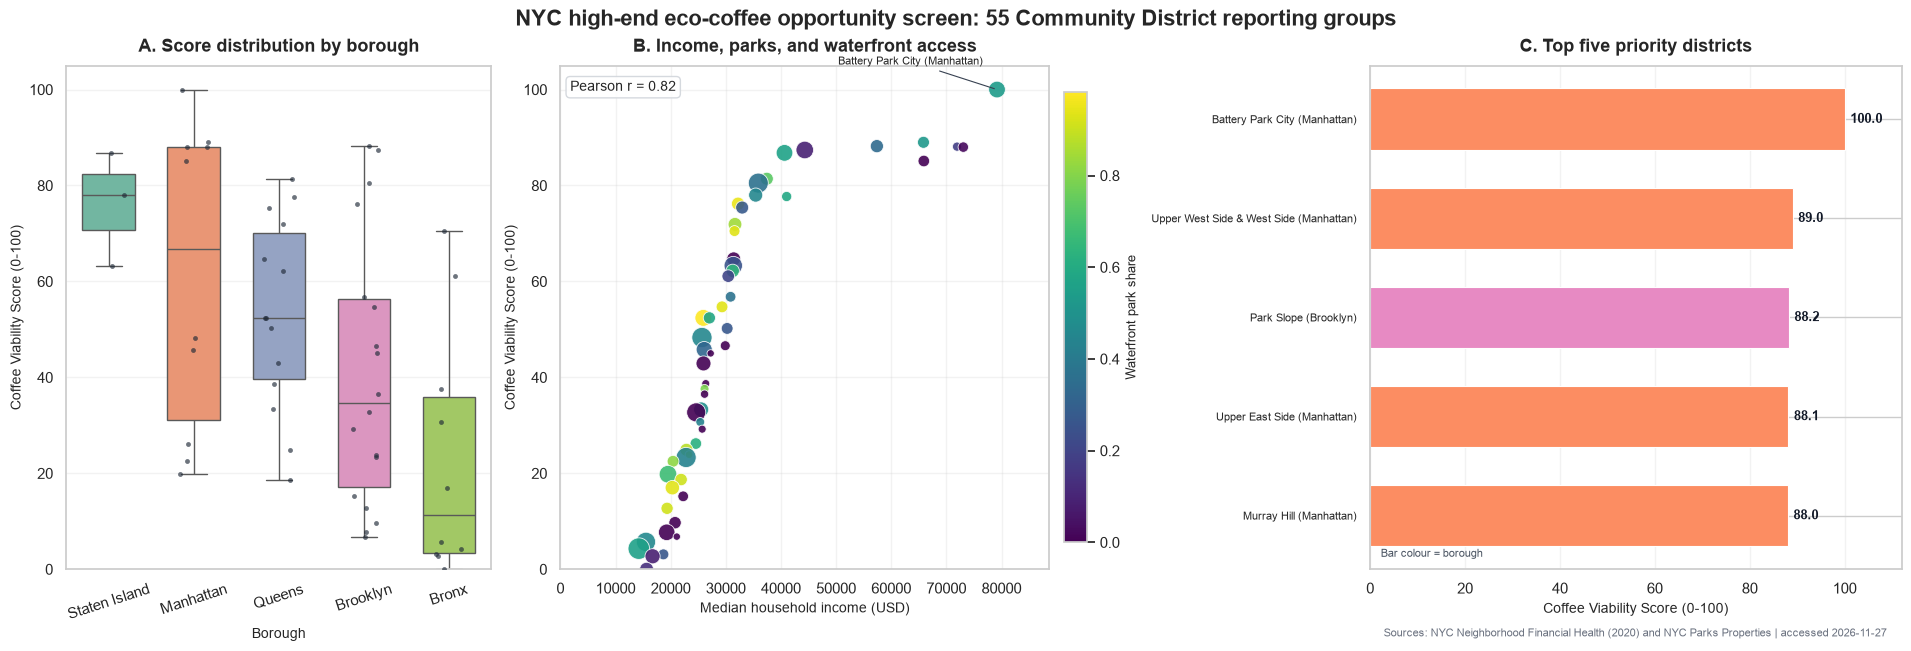

Saved dashboard: C:\Users\STUDENT\Desktop\Amit\HPC\11-ML-DL-OPENVINO\data\processed\capstone_dashboard.png
Score correlation with median income: 0.822
Highest score: Battery Park City (Manhattan) (100.0)


In [6]:
borough_order = (
    merged.groupby("borough")["Coffee_Viability_Score"]
    .median()
    .sort_values(ascending=False)
    .index
    .tolist()
)
borough_palette = dict(zip(borough_order, sns.color_palette("Set2", n_colors=len(borough_order))))

fig = plt.figure(figsize=(19, 6.4), constrained_layout=True)
grid = fig.add_gridspec(1, 3, width_ratios=[1.0, 1.15, 1.25])

ax1 = fig.add_subplot(grid[0, 0])
sns.boxplot(
    data=merged,
    x="borough",
    y="Coffee_Viability_Score",
    order=borough_order,
    palette=borough_palette,
    width=0.62,
    showfliers=False,
    ax=ax1,
)
sns.stripplot(
    data=merged,
    x="borough",
    y="Coffee_Viability_Score",
    order=borough_order,
    color="#1f2937",
    size=3.5,
    alpha=0.65,
    jitter=0.18,
    ax=ax1,
)
ax1.set_title("A. Score distribution by borough", fontsize=13, fontweight="bold", pad=10)
ax1.set_xlabel("Borough", fontsize=10)
ax1.set_ylabel("Coffee Viability Score (0-100)", fontsize=10)
ax1.set_ylim(0, 105)
ax1.tick_params(axis="x", rotation=18)
ax1.grid(axis="y", alpha=0.25)

ax2 = fig.add_subplot(grid[0, 1])
sns.scatterplot(
    data=merged,
    x="median_income",
    y="Coffee_Viability_Score",
    size="park_count",
    hue="waterfront_share",
    palette="viridis",
    sizes=(28, 240),
    alpha=0.9,
    edgecolor="white",
    linewidth=0.6,
    legend=False,
    ax=ax2,
)
ax2.set_title("B. Income, parks, and waterfront access", fontsize=13, fontweight="bold", pad=10)
ax2.set_xlabel("Median household income (USD)", fontsize=10)
ax2.set_ylabel("Coffee Viability Score (0-100)", fontsize=10)
ax2.set_xlim(0, merged["median_income"].max() * 1.12)
ax2.set_ylim(0, 105)
ax2.grid(alpha=0.25)

correlation = merged["median_income"].corr(merged["Coffee_Viability_Score"])
ax2.text(
    0.02,
    0.97,
    f"Pearson r = {correlation:.2f}",
    transform=ax2.transAxes,
    va="top",
    ha="left",
    fontsize=10,
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="#d1d5db", alpha=0.9),
)
best_row = merged.iloc[0]
ax2.annotate(
    best_row["district_short"],
    xy=(best_row["median_income"], best_row["Coffee_Viability_Score"]),
    xytext=(-10, 18),
    textcoords="offset points",
    ha="right",
    fontsize=8,
    arrowprops=dict(arrowstyle="-", color="#374151", lw=0.8),
)
normalizer = plt.Normalize(merged["waterfront_share"].min(), merged["waterfront_share"].max())
sm = plt.cm.ScalarMappable(cmap="viridis", norm=normalizer)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax2, fraction=0.046, pad=0.03)
cbar.set_label("Waterfront park share", fontsize=9)

ax3 = fig.add_subplot(grid[0, 2])
top5_plot = top5.sort_values("Coffee_Viability_Score")
bar_colors = [borough_palette[borough] for borough in top5_plot["borough"]]
bars = ax3.barh(
    top5_plot["district_short"],
    top5_plot["Coffee_Viability_Score"],
    color=bar_colors,
    edgecolor="white",
    linewidth=0.8,
    height=0.62,
)
for bar, score in zip(bars, top5_plot["Coffee_Viability_Score"]):
    ax3.text(
        score + 1.2,
        bar.get_y() + bar.get_height() / 2,
        f"{score:.1f}",
        va="center",
        ha="left",
        fontsize=9,
        fontweight="bold",
        color="#111827",
    )
ax3.set_title("C. Top five priority districts", fontsize=13, fontweight="bold", pad=10)
ax3.set_xlabel("Coffee Viability Score (0-100)", fontsize=10)
ax3.set_ylabel("")
ax3.set_xlim(0, 112)
ax3.grid(axis="x", alpha=0.25)
ax3.tick_params(axis="y", labelsize=8)

ax3.text(
    0.02,
    0.02,
    "Bar colour = borough",
    transform=ax3.transAxes,
    va="bottom",
    ha="left",
    fontsize=8,
    color="#4b5563",
)

fig.suptitle(
    "NYC high-end eco-coffee opportunity screen: 55 Community District reporting groups",
    fontsize=16,
    fontweight="bold",
)
fig.text(
    0.99,
    0.01,
    "Sources: NYC Neighborhood Financial Health (2020) and NYC Parks Properties | accessed 2026-11-27",
    ha="right",
    va="bottom",
    fontsize=8,
    color="#6b7280",
)

figure_path = PROCESSED_DIR / "capstone_dashboard.png"
fig.savefig(figure_path, dpi=200, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved dashboard: {figure_path}")
print(f"Score correlation with median income: {correlation:.3f}")
print(f"Highest score: {merged.iloc[0]['district_short']} ({merged.iloc[0]['Coffee_Viability_Score']:.1f})")


In [7]:
export_columns = [
    "rank",
    "cd",
    "borough",
    "neighborhoods",
    "district_short",
    "median_income",
    "nyc_poverty_rate",
    "park_count",
    "park_acres",
    "waterfront_acres",
    "waterfront_share",
    "Coffee_Viability_Score",
]

export_path = PROCESSED_DIR / "capstone_district_scores.csv"
merged[export_columns].to_csv(export_path, index=False)

print(f"Saved scored district table: {export_path}")
print(f"Top 5:")
for row in merged.head(5).itertuples():
    print(
        f"{row.rank}. {row.district_short}: {row.Coffee_Viability_Score:.1f} "
        f"(income ${row.median_income:,.0f}; poverty {row.nyc_poverty_rate:.1%}; "
        f"parks {row.park_count}; waterfront {row.waterfront_share:.1%})"
    )


Saved scored district table: C:\Users\STUDENT\Desktop\Amit\HPC\11-ML-DL-OPENVINO\data\processed\capstone_district_scores.csv
Top 5:
1. Battery Park City (Manhattan): 100.0 (income $79,181; poverty 8.8%; parks 57; waterfront 53.3%)
2. Upper West Side & West Side (Manhattan): 89.0 (income $65,844; poverty 9.0%; parks 30; waterfront 52.4%)
3. Park Slope (Brooklyn): 88.2 (income $57,393; poverty 9.5%; parks 36; waterfront 33.6%)
4. Upper East Side (Manhattan): 88.1 (income $71,933; poverty 7.3%; parks 18; waterfront 18.1%)
5. Murray Hill (Manhattan): 88.0 (income $73,067; poverty 10.0%; parks 23; waterfront 2.0%)


## 6. What the dashboard says

The top of the ranking is concentrated in Manhattan, with one Brooklyn district in the shortlist:

| Rank | District | Why it rises |
|---:|---|---|
| 1 | Battery Park City, Greenwich Village & Soho | Highest income, low poverty, dense park access, strong waterfront share |
| 2 | Upper West Side & West Side | High income, low poverty, strong park access and waterfront exposure |
| 3 | Park Slope, Carroll Gardens & Red Hook | Strong income and low poverty relative to Brooklyn, with good park count and waterfront access |
| 4 | Upper East Side | High income and very low poverty, with a smaller but still meaningful park footprint |
| 5 | Murray Hill, Gramercy & Stuyvesant Town | High income and low poverty; park access is adequate but not the main driver |

The income relationship is positive and visible in panel B, but it is not the whole story: park count and waterfront share separate otherwise similar districts. The score should be read as a **relative screen**, not as predicted revenue.

## 7. Recommendation and limitations

### Recommended sequence

1. **Battery Park City / Greenwich Village / Soho** — first priority for a flagship. It combines the strongest demand profile with the strongest eco-amenity profile in the data.
2. **Upper West Side / Upper East Side** — second-wave sites for households already paying premium prices for quality and convenience.
3. **Park Slope / Carroll Gardens / Red Hook** — the Brooklyn entry point; validate weekend traffic and family-oriented dayparts.
4. **Murray Hill / Gramercy / Stuyvesant Town** — a value-of-rent option if the flagship lease is too expensive.

### What this model does not include

- Commercial rent and build-out cost.
- Foot traffic, transit adjacency, and daytime versus evening population.
- Direct competitor density (existing cafés, chains, and grocery coffee bars).
- Park quality, programming, and actual pedestrian access.
- Post-2020 demographic change; the NFH release is a 2020 snapshot.

### Next validation steps

1. Collect asking rents and available frontage for the top five districts.
2. Add mobile foot-traffic or transit ridership data for weekday and weekend dayparts.
3. Map existing premium coffee competitors and calculate a 5-minute walk trade area.
4. Score the top ten sites with a rent-adjusted payback model before committing capital.

## 8. Reproducibility

- Run the notebook from `C:\Users\STUDENT\Desktop\Amit\HPC\11-ML-DL-OPENVINO`.
- Raw data are cached under `data/raw/capstone/`; delete the cache to re-download from NYC Open Data.
- Scored output: `data/processed/capstone_district_scores.csv`.
- Dashboard: `data/processed/capstone_dashboard.png`.
- Runtime is short because both source files are small; no external ML model is required.
